<a href="https://colab.research.google.com/github/Ahad1247/tempTest/blob/main/CSX4201_Week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week02 — Introduction to Machine Learning, Part 1

**Name:** MD AHADUR RAHMAN TALUKDER  **Student ID:** 6411247

Save as `Week02-Practice-<studentID>.ipynb` in `Documents/AI-Course/Week02`

## Plot tools
Run this cell once first (code hidden, no need to edit)

In [ ]:
# ===== Plot and loss tools — run this cell once, no need to edit =====
from IPython.display import SVG, HTML, display
from html import escape

X_DATA = [1.0, 1.8, 3.0, 4.1, 5.2, 6.0]   # x: advertising (million THB)
Y_DATA = [1.0, 1.3, 2.2, 2.5, 2.8, 3.6]   # y: profit (million THB)

TXT = {
    "data": "Actual data (y)", "line": "Your line (y′)",
    "over": "Over (y′ > y)", "under": "Under (y′ < y)",
    "xlab": "Advertising x (million THB)", "ylab": "Profit y (million THB)",
    "x": "x", "y": "actual y", "yp": "predicted y′", "err": "error (ignore sign)", "dir": "guess",
    "o": "over", "u": "under", "e": "exact",
    "l1": "L1 loss (sum)", "mae": "MAE",
    "mean": "MAE = {l1:.3f} ÷ {n} ≈ {mae:.3f} → the line is off by about {mae:.3f} million THB per point",
}

FONT = "'Sarabun', 'Noto Sans Thai', 'Leelawadee UI', 'Thonburi', 'Segoe UI', sans-serif"
C_DATA, C_LINE, C_OVER, C_UNDER = "#2563eb", "#ea580c", "#e11d48", "#0284c7"


def _text(x, y, s, size=12, color="#334155", anchor="middle", weight="400"):
    return (f'<text x="{x:.1f}" y="{y:.1f}" font-size="{size}" fill="{color}" '
            f'font-weight="{weight}" text-anchor="{anchor}" font-family="{FONT}">{escape(str(s))}</text>')


def plot_data(x_data=X_DATA, y_data=Y_DATA):
    """Plot only the data points (no model line yet)."""
    plot_line(None, None, x_data, y_data)


def plot_line(m, b, x_data=X_DATA, y_data=Y_DATA):
    """Plot the data, the line y' = m*x + b and the error at every point."""
    has_line = m is not None and b is not None
    W, H = 700, 480
    L, R, T, B = 70, 24, 84, 60
    x0, x1, y0, y1 = 0, 7, 0, 4
    px = lambda x: L + (x - x0) / (x1 - x0) * (W - L - R)
    py = lambda y: H - B - (y - y0) / (y1 - y0) * (H - T - B)
    s = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {W} {H}" width="{W}" height="{H}">',
         f'<rect width="{W}" height="{H}" rx="10" fill="#ffffff"/>',
         f'<rect x="{L}" y="{T}" width="{W-L-R}" height="{H-T-B}" fill="#f8fafc" stroke="#e2e8f0"/>',
         f'<clipPath id="plotarea"><rect x="{L}" y="{T}" width="{W-L-R}" height="{H-T-B}"/></clipPath>']
    for i in range(0, 8):                                   # vertical grid + x ticks
        s.append(f'<line x1="{px(i):.1f}" y1="{T}" x2="{px(i):.1f}" y2="{H-B}" stroke="#e2e8f0"/>')
        s.append(_text(px(i), H - B + 18, i, 11, "#64748b"))
    for k in range(0, 9):                                   # horizontal grid + y ticks
        v = k * 0.5
        s.append(f'<line x1="{L}" y1="{py(v):.1f}" x2="{W-R}" y2="{py(v):.1f}" stroke="#e2e8f0"/>')
        s.append(_text(L - 8, py(v) + 4, f"{v:.1f}", 11, "#64748b", "end"))
    s.append(_text((L + W - R) / 2, H - 16, TXT["xlab"], 13, "#334155", weight="600"))
    s.append(f'<g transform="translate(20 {(T + H - B) / 2:.1f}) rotate(-90)">'
             + _text(0, 0, TXT["ylab"], 13, "#334155", weight="600") + '</g>')
    # the line y' = m x + b (clipped to the plot area)
    if has_line:
      s.append(f'<line x1="{px(0):.1f}" y1="{py(b):.1f}" x2="{px(6.8):.1f}" y2="{py(m * 6.8 + b):.1f}" '
             f'stroke="{C_LINE}" stroke-width="3" clip-path="url(#plotarea)"/>')
    # errors: dotted segment from the point to the line + value label
    for x, y in (zip(x_data, y_data) if has_line else []):
        yp = m * x + b
        c = "#64748b" if abs(y - yp) < 0.005 else (C_OVER if yp > y else C_UNDER)
        s.append(f'<line x1="{px(x):.1f}" y1="{py(y):.1f}" x2="{px(x):.1f}" y2="{py(yp):.1f}" '
                 f'stroke="{c}" stroke-width="2.5" stroke-dasharray="3 3" clip-path="url(#plotarea)"/>')
        ly = min(max(py((y + yp) / 2), T + 10), H - B - 10)
        label = f"{abs(y - yp):.2f}"
        s.append(f'<rect x="{px(x) + 10:.1f}" y="{ly - 10:.1f}" width="40" height="20" rx="5" '
                 f'fill="#ffffff" stroke="{c}"/>')
        s.append(_text(px(x) + 30, ly + 4, label, 12, c, weight="700"))
    for x, y in zip(x_data, y_data):                        # data points on top
        s.append(f'<circle cx="{px(x):.1f}" cy="{py(y):.1f}" r="11" fill="{C_DATA}" fill-opacity="0.15"/>')
        s.append(f'<circle cx="{px(x):.1f}" cy="{py(y):.1f}" r="6" fill="{C_DATA}" stroke="#ffffff" stroke-width="1.5"/>')
        below = has_line and (m * x + b) > y + 0.005   # line above the dot -> put the label under it
        s.append(_text(px(x), py(y) + 26 if below else py(y) - 16, f"({x:.1f}, {y:.1f})", 11, "#1e293b", weight="600"))
    # legend + current equation
    s.append(f'<circle cx="{L + 6}" cy="26" r="6" fill="{C_DATA}"/>' + _text(L + 18, 30, TXT["data"], 13, "#1e293b", "start", "600"))
    if has_line:
        s.append(f'<line x1="{L + 150}" y1="26" x2="{L + 178}" y2="26" stroke="{C_LINE}" stroke-width="3"/>'
                 + _text(L + 186, 30, TXT["line"], 13, "#1e293b", "start", "600"))
        s.append(f'<rect x="{W - 250}" y="20" width="12" height="12" rx="2" fill="{C_OVER}"/>' + _text(W - 233, 30, TXT["over"], 12, C_OVER, "start"))
        s.append(f'<rect x="{W - 125}" y="20" width="12" height="12" rx="2" fill="{C_UNDER}"/>' + _text(W - 108, 30, TXT["under"], 12, C_UNDER, "start"))
        s.append(_text(L, 58, f"y′ = {m:g}x + {b:g}", 15, C_LINE, "start", "700"))
    s.append('</svg>')
    display(SVG("".join(s)))


def show_loss(m, b, x_data=X_DATA, y_data=Y_DATA):
    """Table of errors, L1 loss and MAE for y' = m*x + b."""
    td = 'style="padding:4px 12px;text-align:right;border-bottom:1px solid #e2e8f0"'
    th = 'style="padding:6px 12px;text-align:right;background:#f1f5f9;border-bottom:2px solid #cbd5e1"'
    rows, l1 = [], 0.0
    for x, y in zip(x_data, y_data):
        yp = m * x + b
        err = abs(y - yp)
        l1 += err
        if round(yp - y, 3) > 0:
            d = f'<span style="color:{C_OVER};font-weight:600">{TXT["o"]}</span>'
        elif round(yp - y, 3) < 0:
            d = f'<span style="color:{C_UNDER};font-weight:600">{TXT["u"]}</span>'
        else:
            d = TXT["e"]
        rows.append(f"<tr><td {td}>{x:.1f}</td><td {td}>{y:.1f}</td><td {td}>{yp:.3f}</td>"
                    f"<td {td}>{err:.3f}</td><td {td}>{d}</td></tr>")
    n = len(x_data)
    mae = l1 / n
    rows.append(f'<tr><td {td}></td><td {td}></td><td {td}><b>{TXT["l1"]}</b></td><td {td}><b>{l1:.3f}</b></td><td {td}></td></tr>')
    rows.append(f'<tr><td {td}></td><td {td}></td><td {td}><b>{TXT["mae"]}</b> = {l1:.3f} ÷ {n}</td>'
                f'<td {td}><b>≈ {mae:.3f}</b></td><td {td}></td></tr>')
    head = "".join(f"<th {th}>{TXT[k]}</th>" for k in ["x", "y", "yp", "err", "dir"])
    display(HTML(f'<table style="border-collapse:collapse;background:#fff;color:#1e293b;font-family:{FONT};font-size:14px">'
                 f"<tr>{head}</tr>{''.join(rows)}</table>"))
    print(TXT["mean"].format(l1=l1, n=n, mae=mae))
    return mae

## B0–B2 Setup and Python basics
Run this cell once (Shift + Enter)

── B0 check Python ──
/usr/bin/python3
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
── B2.1 variables ──
1.735
── B2.2 f-string ──
x = 2.5  y = 1.74
── B2.3 lists ──
6 1.0 6.0 2.2
── B2.4 for ──
x = 2.0  y = 1.49
x = 2.5  y = 1.74
x = 3.0  y = 1.98
x = 5.0  y = 2.96


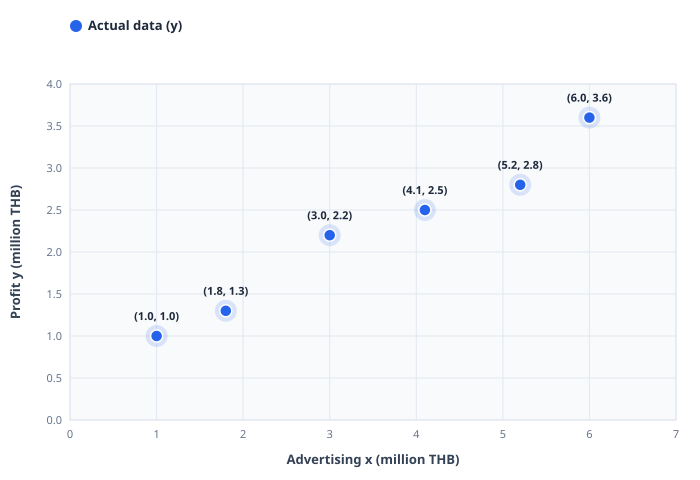

In [ ]:
# B0 check Python
import sys
print("── B0 check Python ──")
print(sys.executable)
print(sys.version)

# B2.1 variables and arithmetic
m = 0.49
b = 0.51
x = 2.5
y = m * x + b
print("── B2.1 variables ──")
print(y)

# B2.2 f-string (2 decimal places)
print("── B2.2 f-string ──")
print(f"x = {x}  y = {y:.2f}")

# B2.3 lists (index starts at 0)
x_data = [1.0, 1.8, 3.0, 4.1, 5.2, 6.0]   # advertising (million THB)
y_data = [1.0, 1.3, 2.2, 2.5, 2.8, 3.6]   # profit (million THB)
print("── B2.3 lists ──")
print(len(x_data), x_data[0], x_data[-1], y_data[2])

# B2.4 for loop (repeat for every item)
print("── B2.4 for ──")
for k in [2.0, 2.5, 3.0, 5.0]:
    print(f"x = {k}  y = {m * k + b:.2f}")

# look at the data on a plot (no model line yet)
plot_data(x_data, y_data)

## B3. Workshop 1: tune the line
Change only `m` and `b` to get the **lowest MAE**

### B3.1 Set m and b, then plot

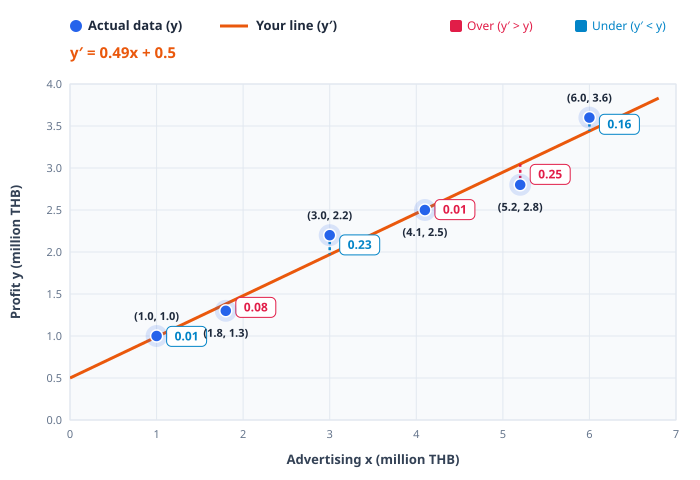

In [ ]:
m = 0.49  # slope        <-- change
b = 0.5    # y-intercept  <-- change

plot_line(m, b)


### B3.2 Check L1 loss and MAE
Change m, b in B3.1, then run B3.1 → B3.2 again until MAE is as low as you can get

In [ ]:
show_loss(m, b)

x,actual y,predicted y′,error (ignore sign),guess
1.0,1.0,0.990,0.010,under
1.8,1.3,1.382,0.082,over
3.0,2.2,1.970,0.230,under
4.1,2.5,2.509,0.009,over
5.2,2.8,3.048,0.248,over
6.0,3.6,3.440,0.160,under
,,L1 loss (sum),0.739,
,,MAE = 0.739 ÷ 6,≈ 0.123,


MAE = 0.739 ÷ 6 ≈ 0.123 → the line is off by about 0.123 million THB per point


0.12316666666666676